In [1]:
# ============================================================
# Example
# ============================================================

In [2]:
import numpy as np
import matplotlib.pyplot as plt 
import sys

sys.path.append(r"C:\Users\jose1\OneDrive\PostDoc_FZU\Calculators\AnalyticalSolvers")

import AFM_inPlane as afm_inp

In [3]:
# ============================================================
# Setup
# ============================================================
afm_inp.validate_afmr_limit()
print()
afm_inp.validate_dmi_limit()
print()
afm_inp.validate_spin_flop_state()

# --- example: easy-plane AFM + DMI + weak in-plane anisotropy -----
p = afm_inp.AFMParams.from_fields(
    Ms=2e5, BE=1000.0, Bh=0.1, Bip=0.000001, BD=0.05,
    A=1e-12, A12=-1e-12,
)

AFMR zero-field validation (no DMI)
-----------------------------------
  in-plane    expected  12.56756 GHz
  out-of-pl.  expected  41.57811 GHz
  calculated            12.56756,  41.57811 GHz
  relative error: [1.73015109e-14 2.38544095e-15]

DMI zero-field validation
-------------------------
  angle between sublattices: 177.13759 deg (expected 177.13759)
  out-of-plane mode expected 42.06222 GHz, calculated 42.06222 GHz
  Goldstone mode: 0.00e+00 GHz

Field-induced canting validation
--------------------------------
  |m| calculated 0.100000, expected 0.100000
  l . B = 5.34e-16 (should be 0)


(<Figure size 1000x400 with 2 Axes>,
 array([<Axes: xlabel='B (T)', ylabel='deg'>,
        <Axes: xlabel='B (T)', ylabel='net moment $(\\mathbf{m}_1+\\mathbf{m}_2)/2$'>],
       dtype=object))

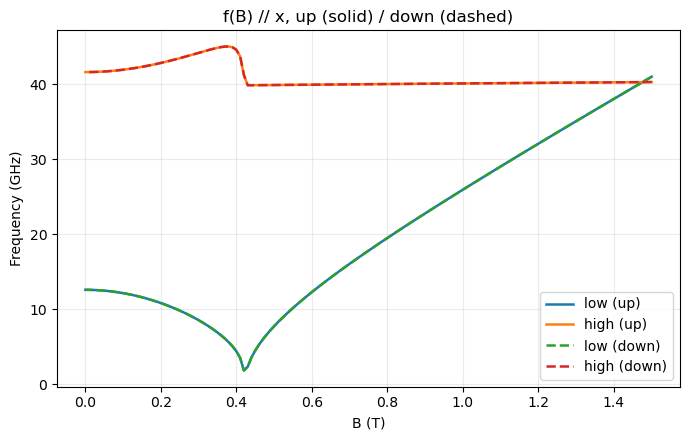

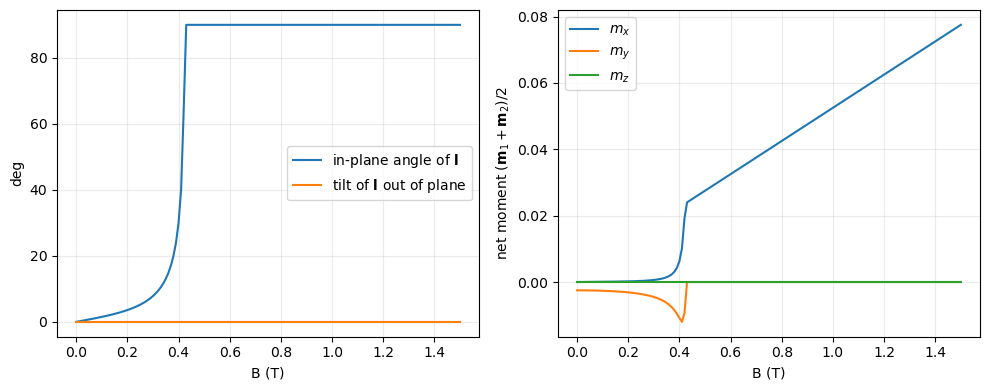

In [4]:
# ============================================================
# f(H), field along the in-plane easy axis (x), up and down sweeps
# ============================================================
fields = np.linspace(0.0, 1.5, 151)
f_up, _, res_up = afm_inp.sweep_field(fields, [1, 0, 0], p, follow=True)
f_dn, _, res_dn = afm_inp.sweep_field(fields[::-1], [1, 0, 0], p, follow=True)
f_dn = f_dn[:, np.argsort(f_dn[-1])]   # label branches by their B=0 order
fig, ax = afm_inp.plot_frequency_sweep(fields, f_up, "B (T)", title="f(B) // x, up (solid) / down (dashed)",
                               labels=["low (up)", "high (up)"])
afm_inp.plot_frequency_sweep(fields[::-1], f_dn, "B (T)", ax=ax, ls="--",
                     labels=["low (down)", "high (down)"])
afm_inp.plot_equilibrium(fields, res_up, "B (T)")


NameError: name 'describe_mode' is not defined

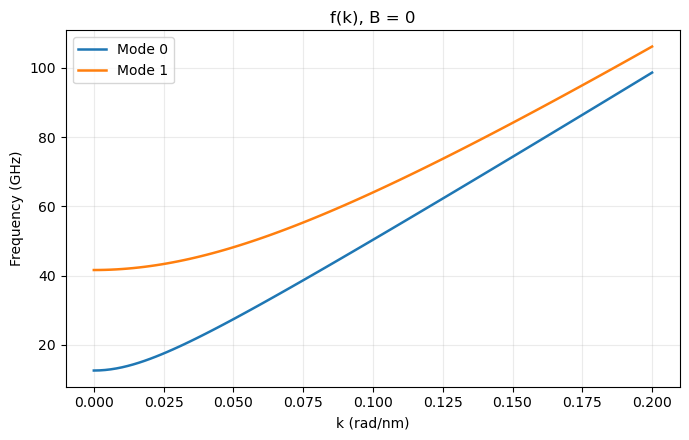

In [5]:
# ============================================================
# f(k) at zero field
# ============================================================
ks = np.linspace(0, 2e8, 100)
f_k, _, res_k = afm_inp.sweep_wavevector(ks, np.zeros(3), p)
afm_inp.plot_frequency_sweep(ks * 1e-9, f_k, "k (rad/nm)", title="f(k), B = 0")

# mode shapes at B = 0, k = 0
r0 = afm_inp.solve_modes(0.0, np.zeros(3), p)
for j in range(2):
    print(describe_mode(r0, j))
    afm_inp.plot_mode(r0, j)

plt.show()